# Fitting the pair source with a normalizing flow

Fits a model of the 3D pair-separation source `S(r)` so that
`C(q) = < K(|q|, |r|, angle(q, r)) >_{r ~ S}` reproduces the tabulated correlation function `65.dat`.
`K` is the kernel `Kl-ppiplus.dat` (a 100x100x100 table in `|q|`, `|r|`, `theta`).

Three source models are trained and compared against the *true* source samples `ppi-0.65.dat`
(500k points `(x, y, z)` in fm):

1. **Gaussian** - `r = L z + mu` (the model of the original notebook).
2. **RealNVP** - affine coupling layers followed by the same affine map, so it contains the Gaussian as a special case.
3. **Levy** - the Gaussian latent is replaced by independent **alpha-stable** components whose stability index `alpha` (tail exponent) and
   skewness `beta` are **trained** for each axis, followed by the same affine map. `alpha = 2` is the Gaussian, `alpha < 2` gives power-law tails.

### Fixes compared with the previous version
* `Cholesky` bijector: the **diagonal of `L` is now forced positive** (softplus). Before, the comment claimed this but the raw
  entries were used, so `log(diag)` could become NaN during training.
* The **shift (mean) was a variable that was never used** (and initialised at `7` while the target mean was `4`). It is now applied in
  `forward`/`inverse`, so the source centre is actually fitted.
* The loss could produce **NaN gradients**: `acos` has an infinite derivative at `+-1` (the clip only protected the value, not the
  gradient), and `q = 0` / `r = 0` gave `0/0`. Now the ratio is clipped to `[-1+1e-6, 1-1e-6]` and magnitudes get a tiny epsilon; `q = 0` is excluded from the grid.
* The unused `lr_decay` is replaced by a cosine learning-rate schedule; the dead `KL_Divergence` duplicate of the loss was removed.

In [2]:
import os, importlib.util
# TFP is not compatible with Keras 3: it needs the legacy Keras 2 package `tf-keras` (pip install tf-keras).
if importlib.util.find_spec('tf_keras') is not None:
    os.environ.setdefault('TF_USE_LEGACY_KERAS', '1')      # must be set BEFORE `import tensorflow`
# macOS kernel dying with "OMP: Error #15 ... libomp already initialized"?  (unsafe workaround, last resort)
# os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import tensorflow as tf
import tensorflow_probability as tfp
import time
import numpy as np
# For convenience
tfd = tfp.distributions
tfb = tfp.bijectors
DTYPE=np.float32
import matplotlib.pyplot as plt
plt.rcParams.update({'xtick.top': True, 'ytick.right': True, 'xtick.direction': 'in', 'ytick.direction': 'in',
                     'xtick.minor.visible': True, 'ytick.minor.visible': True})

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 1.7 MB/s  0:00:051.7 MB/s eta 0:00:01:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 1.8 MB/s  0:00:01m 1.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 1.8 MB/s  0:00:02m 1.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]


Matplotlib is building the font cache; this may take a moment.


In [3]:
class RegularGridInterpolator:
    """
    A reusable nD linear interpolator.
    
    Initializes once with the reference grid and values. The object can then be
    called repeatedly with new query points for fast, graph-based interpolation.
    """
    def __init__(self, x_ref_min, x_ref_max, y_ref):
        # --- ONE-TIME SETUP ---
        # Store grid data as TensorFlow constants to embed them in the graph.
        self.x_ref_min = tf.constant(x_ref_min, dtype=tf.float32)
        self.x_ref_max = tf.constant(x_ref_max, dtype=tf.float32)
        self.y_ref = tf.constant(y_ref, dtype=tf.float32)

    @tf.function
    def __call__(self, x_query):
        """
        Performs interpolation. This method is compiled into a static graph
        by @tf.function for high performance.
        
        Args:
            x_query: A tensor of x-coordinates to interpolate.
        
        Returns:
            A tensor of interpolated y-values.
        """
        # --- REPEATED, FAST EXECUTION ---
        return tfp.math.batch_interp_regular_nd_grid(
            x=x_query, 
            x_ref_min=self.x_ref_min, 
            x_ref_max=self.x_ref_max, 
            y_ref=self.y_ref,
            axis=-3
        )

# --- Usage ---
y_values = np.reshape(np.loadtxt("Kl-ppiplus.dat"), (100, 100, 100))   # axes: |q|, |r|, theta
x_min = [0, 0, 0]
x_max = [100, 40, np.pi]                                                # |q| [MeV/c], |r| [fm], theta [rad]
interpolator = RegularGridInterpolator(x_ref_min=x_min, x_ref_max=x_max, y_ref=y_values)

## Initial guess for the source (same as before)

In [4]:
init_mean = np.array([4.0, 0.0, -0.5], dtype=np.float32)
init_cov = np.diag([80.0, 30.0, 30.0]).astype(np.float32)
base_distribution = tfd.MultivariateNormalDiag(loc=tf.zeros(3), scale_diag=tf.ones(3))

## Gaussian source: `r = L z + mu` with `L` lower-triangular and positive diagonal

In [5]:
class Cholesky(tfb.Bijector):
    """y = L x + shift;  L lower triangular with strictly positive diagonal (softplus + 1e-3)."""
    def __init__(self, mean, covariance, name='TrainableCholesky'):
        super().__init__(forward_min_event_ndims=1, validate_args=False, name=name)
        L0 = np.linalg.cholesky(np.asarray(covariance, dtype=np.float64))
        self._tril = np.stack(np.tril_indices(3, -1), axis=1).astype(np.int32)       # (1,0), (2,0), (2,1)
        raw_diag = np.log(np.expm1(np.diag(L0) - 1e-3))                               # inverse softplus
        self._raw_diag = tf.Variable(raw_diag, dtype=DTYPE, name='raw_diag')
        self._off_diag = tf.Variable(L0[np.tril_indices(3, -1)], dtype=DTYPE, name='off_diag')
        self._shift = tf.Variable(np.asarray(mean), dtype=DTYPE, name='shift')

    def _diag(self):
        return tf.math.softplus(self._raw_diag) + 1e-3

    def _L(self):
        return tf.scatter_nd(self._tril, self._off_diag, [3, 3]) + tf.linalg.diag(self._diag())

    def _forward(self, x):
        return tf.linalg.matvec(self._L(), x) + self._shift

    def _inverse(self, y):
        Linv = tf.linalg.triangular_solve(self._L(), tf.eye(3, dtype=DTYPE), lower=True)      # 3x3 inverse of L
        return tf.linalg.matvec(Linv, y - self._shift)

    def _forward_log_det_jacobian(self, x):
        return tf.reduce_sum(tf.math.log(self._diag()))

    def _inverse_log_det_jacobian(self, y):
        return -tf.reduce_sum(tf.math.log(self._diag()))

gauss_bijector = Cholesky(init_mean, init_cov)
gauss_flow = tfd.TransformedDistribution(distribution=base_distribution, bijector=gauss_bijector)
gauss_vars = list(gauss_bijector.trainable_variables)

# sanity check: the untrained model must reproduce the initial guess
s = gauss_flow.sample(200000).numpy()
print('mean', s.mean(0), '\ncov\n', np.cov(s.T))

mean [ 4.010353e+00  2.183769e-03 -5.198249e-01] 
cov
 [[ 8.00965743e+01  1.38415495e-01  1.18327985e-01]
 [ 1.38415495e-01  3.00604749e+01 -6.66021486e-03]
 [ 1.18327985e-01 -6.66021486e-03  2.99646438e+01]]


## Loss: `|| <K>_r - C ||`  (numerically safe version)

In [6]:
@tf.function
def compute_loss(xs, true_ys, qs, interpolator):
    eps = 1e-6
    r = tf.norm(xs, axis=1) + eps                            # [N]
    q = tf.norm(qs, axis=1) + eps                            # [M]
    dot_products = tf.tensordot(qs, xs, axes=[[1], [1]])     # [M, N]
    ratio = dot_products / tf.tensordot(q, r, axes=0)
    # acos has an infinite slope at +-1: clip *inside* the interval so the gradient stays finite
    angle = tf.math.acos(tf.clip_by_value(ratio, -1.0 + 1e-6, 1.0 - 1e-6))
    q_grid, r_grid = tf.meshgrid(q, r, indexing="ij")
    coords = tf.stack([q_grid, r_grid, angle], axis=-1)      # [M, N, 3]
    mean_ys = tf.math.reduce_mean(interpolator(coords), axis=1)
    return tf.norm(mean_ys - true_ys)

## Data: q grid, target correlation function, and the true source samples

In [7]:
q_max, Nqs = 50, 20
g = (-q_max + 2 * q_max / Nqs * np.arange(Nqs)).astype(np.float32)
qs = np.stack(np.meshgrid(g, g, g, indexing='ij'), axis=-1).reshape(-1, 3)   # same order as the old triple loop
true_Cq = np.loadtxt("65.dat", dtype=np.float32)
nonzero = np.where(np.linalg.norm(qs, axis=1) > 0)[0]                         # q = 0 has no direction
train_idx = nonzero[::8]                                                       # 1000 q points, as before

true_source = np.loadtxt("ppi-0.65.dat")                                       # 500k samples of the real source [fm]
print('true source: mean', true_source.mean(0).round(2), ' std', true_source.std(0).round(2))

true source: mean [ 7.26  0.01 -0.63]  std [8.41 5.2  5.45]


## Training helper

In [9]:
def train(flow, variables, n_steps=3000, n_samples=1000, lr=2e-3, log_every=250):
    schedule = tf.keras.optimizers.schedules.CosineDecay(lr, n_steps, alpha=0.03)
    optimizer = tf.keras.optimizers.legacy.Adam(schedule)
    q_tr, c_tr = tf.constant(qs[train_idx]), tf.constant(true_Cq[train_idx])

    @tf.function
    def step():
        with tf.GradientTape() as tape:
            xs = flow.sample(n_samples)
            loss = compute_loss(xs, c_tr, q_tr, interpolator)
        grads = tape.gradient(loss, variables)
        optimizer.apply_gradients(zip(grads, variables))
        return loss

    history = []
    for i in range(n_steps):
        history.append(float(step()))
        if i % log_every == 0 or i == n_steps - 1:
            print(f'step {i:5d}  loss {np.mean(history[-log_every:]):.5f}')
    return np.array(history)

hist_gauss = train(gauss_flow, gauss_vars, n_steps=1500, lr=5e-3)

step     0  loss 0.25578
step   250  loss 0.14797
step   500  loss 0.13207
step   750  loss 0.11726
step  1000  loss 0.11180
step  1250  loss 0.11137
step  1499  loss 0.10600


## RealNVP source

Six affine coupling layers (`y_b = x_b * exp(s(x_a)) + t(x_a)`, `s, t` from a small tanh MLP), with a rotation of the coordinates between
layers, followed by the same trainable `Cholesky` affine map as above. The last layer of every MLP is initialised to zero, so the untrained
model is *exactly* the Gaussian initial guess and training starts from the same loss.

**Review notes (what limits this model)**
* The wiring is correct: `tfb.Chain` applies its list right-to-left, so the first coupling layer acts first and the affine map last; the zero-initialised
  last layer makes the untrained flow exactly the Gaussian guess; every coordinate is conditioned on the others through the `Permute`.
* The log-scale is hard-bounded (`1.5 * tanh`) and the conditioner is a `tanh` MLP, which **saturates for large `|x|`**. In the tails the coupling
  layer therefore degenerates to a constant shift and scale, so a Gaussian base stays *Gaussian-tailed*: this model can reshape the bulk but cannot
  produce exponential or power-law tails. (More layers do not fix this.)
* The correlator loss uses only `n_samples = 1000` points per step, so `<K>` has a statistical noise floor of about `std(K)/sqrt(1000)`; the
  optimiser cannot go below it, which favours smooth sources. Use 4000+ samples for the final polishing steps.
* The bulk of the density is what `C(q)` is sensitive to, so the problem is also ill-posed (see the closed test in the README).


In [23]:
def build_realnvp(n_layers=6, hidden=32, log_scale_max=1.5, mean=None, cov=None):
    layers, variables = [], []
    for k in range(n_layers):
        n_masked = 1 if k % 2 == 0 else 2
        net = tf.keras.Sequential([
            tf.keras.layers.Dense(hidden, activation='tanh'),
            tf.keras.layers.Dense(2 * (3 - n_masked), kernel_initializer='zeros', bias_initializer='zeros')])
        net.build((None, n_masked))
        def shift_and_log_scale_fn(x0, output_units, _net=net, **kwargs):
            shift, raw = tf.split(_net(x0), 2, axis=-1)
            return shift, log_scale_max * tf.math.tanh(raw)            # bounded log-scale keeps training stable
        layers.append(tfb.RealNVP(num_masked=n_masked, shift_and_log_scale_fn=shift_and_log_scale_fn))
        layers.append(tfb.Permute([1, 2, 0]))
        variables += net.trainable_variables
    affine = Cholesky(init_mean if mean is None else mean, init_cov if cov is None else cov)
    variables += affine.trainable_variables
    # tfb.Chain applies its list right-to-left, so reverse: first coupling layer acts first, affine map last
    bijector = tfb.Chain([affine] + layers[::-1])
    return tfd.TransformedDistribution(distribution=base_distribution, bijector=bijector), variables

nvp_flow, nvp_vars = build_realnvp()
hist_nvp = train(nvp_flow, nvp_vars, n_steps=3000, n_samples=4000, lr=2e-3)

step     0  loss 0.23729
step   250  loss 0.10932
step   500  loss 0.11064
step   750  loss 0.10216
step  1000  loss 0.11038


KeyboardInterrupt: 

In [33]:
hist_nvp = train(nvp_flow, nvp_vars, n_steps=1000, n_samples=4000, lr=2e-3)

step     0  loss 0.03742
step   250  loss 0.06164
step   500  loss 0.05841
step   750  loss 0.05555
step   999  loss 0.05497


## Levy (alpha-stable) source with trainable `alpha` and `beta`

Latent variables `z_i` (i = x, y, z) are i.i.d. per axis from a **stable distribution** with trainable stability index `alpha_i in (1.1, 2)` and skewness
`beta_i in (-1, 1)`, followed by the trainable `Cholesky` affine map (which supplies scale, correlations and the centre). `alpha = 2` is exactly
`N(0,1)` (scaled by `1/sqrt(2)`), so the Gaussian model is the limiting case.

TFP has no stable distribution, so it is sampled with the **Chambers-Mallows-Stuck** formula from fixed uniform / exponential noise. That is
differentiable in `alpha` and `beta`, so they are trained by the same gradient step as every other parameter (the loss only needs samples, no density).
Samples are clipped to `|z| <= 30` so that extreme tail draws cannot produce `inf`/`NaN` (the kernel is flat outside its table anyway).
The sampler was checked against `scipy.stats.levy_stable` (KS statistic about 0.002 - 0.003 for several `(alpha, beta)`).

In [11]:
class LevyBase(tf.Module):
    """Per-axis symmetric/skewed alpha-stable latent z (Chambers-Mallows-Stuck), S1 parametrisation, scale 1/sqrt(2).
       alpha_i = alpha_min + (2 - alpha_min) * sigmoid(raw_alpha_i)   in (alpha_min, 2)
       beta_i  = tanh(raw_beta_i)                                      in (-1, 1)   (irrelevant at alpha = 2)"""
    def __init__(self, alpha0=1.9, beta0=0.0, alpha_min=1.1, learn_alpha=True, learn_beta=True, clip=30.0, name='LevyBase'):
        super().__init__(name=name)
        self.alpha_min, self.clip = alpha_min, clip
        p = (alpha0 - alpha_min) / (2.0 - alpha_min)
        self.raw_alpha = tf.Variable(np.full(3, np.log(p / (1 - p))), dtype=DTYPE, trainable=learn_alpha, name='raw_alpha')
        self.raw_beta = tf.Variable(np.full(3, np.arctanh(beta0)), dtype=DTYPE, trainable=learn_beta, name='raw_beta')

    def alpha(self):
        return self.alpha_min + (2.0 - self.alpha_min) * tf.math.sigmoid(self.raw_alpha)

    def beta(self):
        return tf.math.tanh(self.raw_beta)

    def sample(self, n):
        a, b = self.alpha(), self.beta()
        V = (tf.random.uniform([n, 3], dtype=DTYPE) - 0.5) * np.pi * (1 - 2e-3)           # uniform on (-pi/2, pi/2)
        W = -tf.math.log(tf.random.uniform([n, 3], 1e-7, 1.0, dtype=DTYPE))              # Exp(1)
        t = tf.math.tan(np.pi * a / 2)
        B = tf.math.atan(b * t) / a
        S = (1 + (b * t) ** 2) ** (1 / (2 * a))
        c = tf.maximum(tf.math.cos(V - a * (V + B)), 1e-12)
        x = S * tf.math.sin(a * (V + B)) / tf.math.pow(tf.math.cos(V), 1 / a) * tf.math.pow(c / W, (1 - a) / a)
        return tf.clip_by_value(x / np.sqrt(2.0), -self.clip, self.clip)


class LevyFlow(tf.Module):
    """r = Cholesky( z ),  z ~ per-axis Levy-stable.  `.sample(n)` is all the training loop needs."""
    def __init__(self, alpha0=1.9, beta0=0.0, mean=None, cov=None, **kw):
        super().__init__(name='LevyFlow')
        self.base = LevyBase(alpha0, beta0, **kw)
        self.affine = Cholesky(init_mean if mean is None else mean, init_cov if cov is None else cov)
        self.variables_to_train = list(self.base.trainable_variables) + list(self.affine.trainable_variables)

    def sample(self, n):
        return self.affine.forward(self.base.sample(n))

    def summary(self):
        a, b = self.base.alpha().numpy(), self.base.beta().numpy()
        print('alpha (x, y, z):', a.round(3), '   beta (x, y, z):', b.round(3))
        print('shift:', self.affine._shift.numpy().round(2), '\nL =\n', self.affine._L().numpy().round(2))


levy_flow = LevyFlow(alpha0=1.9, beta0=0.0)                 # start close to Gaussian; alpha, beta are trained
levy_vars = levy_flow.variables_to_train
s = levy_flow.sample(20000).numpy(); print('untrained: finite =', bool(np.isfinite(s).all()), ' median |r| =', np.median(np.linalg.norm(s, axis=1)).round(2))
hist_levy = train(levy_flow, levy_vars, n_steps=1500, lr=3e-3)
levy_flow.summary()

untrained: finite = True  median |r| = 10.68
step     0  loss 0.17330
step   250  loss 0.16372
step   500  loss 0.14326
step   750  loss 0.13202
step  1000  loss 0.12164
step  1250  loss 0.12248
step  1499  loss 0.11860
alpha (x, y, z): [1.873 1.902 1.891]    beta (x, y, z): [-0.464  0.062  0.332]
shift: [ 4.57 -0.06 -0.78] 
L =
 [[8.25 0.   0.  ]
 [0.12 6.   0.  ]
 [0.35 0.08 4.61]]


## Compare the fitted sources with the real one

source                      rms(C - C_65)   mean                    std
true source (ppi-0.65)            0.00624   [ 7.29  0.02 -0.63]   [8.37 5.21 5.44]
Gaussian fit                      0.00244   [ 5.    0.12 -0.83]   [7.93 6.62 4.44]
RealNVP fit                       0.00109   [ 7.24 -0.2  -0.49]   [8.62 7.26 5.17]
Levy fit                          0.00277   [ 4.65 -0.04 -0.81]   [9.12 6.38 4.98]


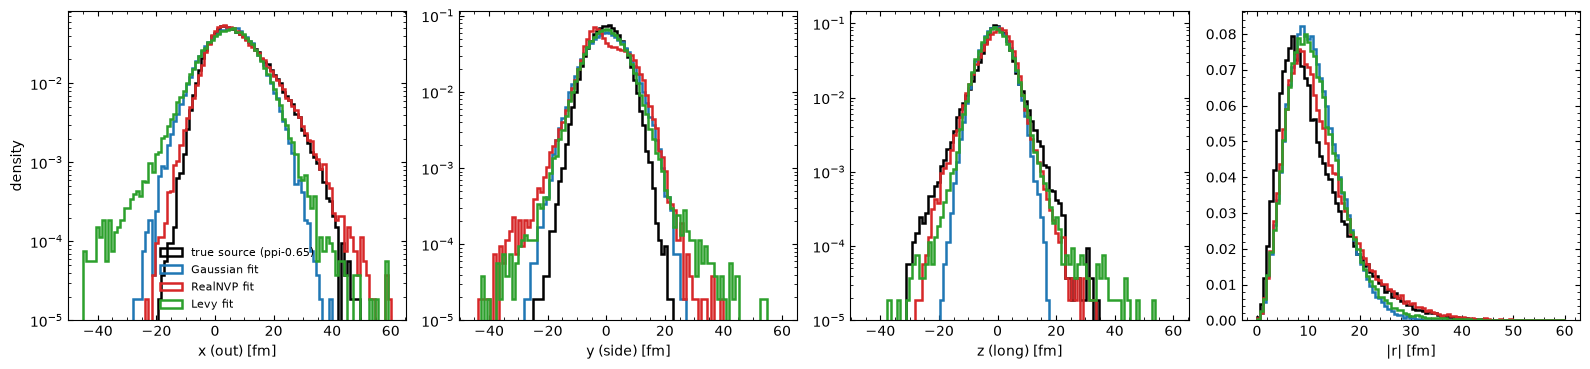

In [34]:
n_eval = 50000
models = {'Gaussian fit': gauss_flow.sample(n_eval).numpy(), 'RealNVP fit': nvp_flow.sample(n_eval).numpy(), 'Levy fit': levy_flow.sample(n_eval).numpy()}
colors = {'true source (ppi-0.65)': 'k', 'Gaussian fit': 'tab:blue', 'RealNVP fit': 'tab:red', 'Levy fit': 'tab:green'}
samples = {'true source (ppi-0.65)': true_source[:n_eval], **models}

def correlation_np(src, q_points, chunk=250):
    out = []
    for i in range(0, len(q_points), chunk):
        xs, qc = tf.constant(src, tf.float32), tf.constant(q_points[i:i + chunk])
        r = tf.norm(xs, axis=1) + 1e-6; q = tf.norm(qc, axis=1) + 1e-6
        ratio = tf.tensordot(qc, xs, axes=[[1], [1]]) / tf.tensordot(q, r, axes=0)
        ang = tf.math.acos(tf.clip_by_value(ratio, -1 + 1e-6, 1 - 1e-6))
        qg, rg = tf.meshgrid(q, r, indexing='ij')
        out.append(tf.reduce_mean(interpolator(tf.stack([qg, rg, ang], -1)), axis=1).numpy())
    return np.concatenate(out)

print(f"{'source':26s} {'rms(C - C_65)':>14s}   mean                    std")
for name, s in samples.items():
    c = correlation_np(s, qs[nonzero])
    print(f"{name:26s} {np.sqrt(np.mean((c - true_Cq[nonzero])**2)):14.5f}   {s.mean(0).round(2)}   {s.std(0).round(2)}")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for i, label in enumerate(['x (out) [fm]', 'y (side) [fm]', 'z (long) [fm]']):
    bins = np.linspace(-45, 60, 100)
    for name, s in samples.items():
        ax[i].hist(s[:, i], bins=bins, density=True, histtype='step', color=colors[name], lw=1.8, label=name)
    ax[i].set_yscale('log'); ax[i].set_ylim(1e-5, None); ax[i].set_xlabel(label)
for name, s in samples.items():
    ax[3].hist(np.linalg.norm(s, axis=1), bins=np.linspace(0, 60, 100), density=True, histtype='step', color=colors[name], lw=1.8)
ax[3].set_xlabel('|r| [fm]'); ax[0].set_ylabel('density'); ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

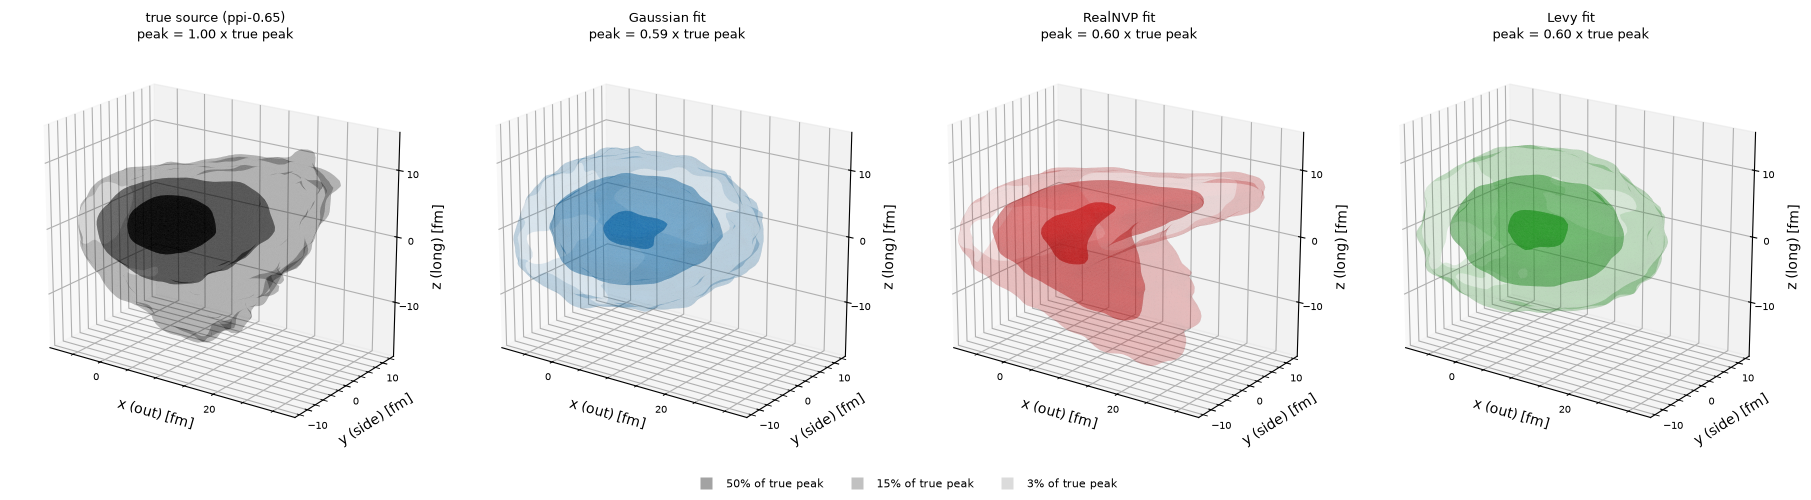

In [35]:
# Transparent iso-density surfaces of the 3D KDE: one panel per source (true source first), each in its own colour.
# needs: pip install scikit-image
from scipy.ndimage import gaussian_filter
from skimage.measure import marching_cubes
from matplotlib.colors import to_rgb
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# ---------------- settings ----------------
G        = 56                       # grid points per axis
BW       = 0.8                      # bandwidth = BW * Scott's rule per axis (smaller = sharper, noisier)
LEVELS   = [0.5, 0.15, 0.03]        # iso-surfaces at these fractions of the TRUE source's peak density
ALPHAS   = [0.60, 0.30, 0.14]       # inner shells more opaque, outer ones more transparent
WINDOW   = (0.5, 99.5)              # plot window: these percentiles of the true source, per axis
AX = ['x (out) [fm]', 'y (side) [fm]', 'z (long) [fm]']
# -------------------------------------------

truth = list(samples)[0]            # 'true source (ppi-0.65)'
panels = list(samples)               # true source first, then the fitted flows
lo, hi = np.percentile(samples[truth], WINDOW, axis=0)
edges = [np.linspace(lo[i], hi[i], G + 1) for i in range(3)]
dx = np.array([e[1] - e[0] for e in edges])
origin = np.array([0.5 * (e[0] + e[1]) for e in edges])             # centre of voxel (0, 0, 0)

def kde_grid(s):
    """binned Gaussian KDE: histogram -> Gaussian smoothing with Scott bandwidth per axis"""
    h, _ = np.histogramdd(s, bins=edges)
    sigma = BW * len(s) ** (-1.0 / 7.0) * s.std(axis=0) / dx        # bandwidth in grid cells
    return gaussian_filter(h, sigma, mode='constant') / (len(s) * dx.prod())

vols = {nm: kde_grid(samples[nm]) for nm in samples}
peak = vols[truth].max()
levels = [f * peak for f in LEVELS]
light = np.array([0.4, -0.5, 0.8]); light /= np.linalg.norm(light)

def shell(vol, level, rgb, alpha):
    verts, faces, _, _ = marching_cubes(vol, level=level, spacing=tuple(dx))
    tri = (verts + origin)[faces]
    nrm = np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0]); nrm /= np.linalg.norm(nrm, axis=1, keepdims=True) + 1e-12
    shade = 0.78 + 0.22 * np.abs(nrm @ light)                       # simple two-sided Lambert shading
    fc = np.empty((len(tri), 4)); fc[:, :3] = np.array(rgb) * shade[:, None]; fc[:, 3] = alpha
    return Poly3DCollection(tri, facecolors=fc, edgecolors='none')

fig = plt.figure(figsize=(4.6 * len(panels), 5.0))
for k, name in enumerate(panels):
    ax = fig.add_subplot(1, len(panels), k + 1, projection='3d')
    for lev, al in zip(levels, ALPHAS):
        try:
            ax.add_collection3d(shell(vols[name], lev, to_rgb(colors[name]), al))
        except ValueError:                                          # no density above this level for this model
            pass
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect(hi - lo); ax.view_init(elev=20, azim=-55)
    ax.set_xlabel(AX[0], labelpad=-3); ax.set_ylabel(AX[1], labelpad=-3); ax.set_zlabel(AX[2], labelpad=-3)
    ax.tick_params(labelsize=7, pad=-2); ax.locator_params(nbins=4)
    ax.set_title(f'{name}\npeak = {vols[name].max() / peak:.2f} x true peak', fontsize=9, pad=-2)
fig.subplots_adjust(left=0.0, right=0.96, top=0.92, bottom=0.07, wspace=0.10)
handles = [plt.Line2D([0], [0], marker='s', ls='', ms=9, mfc='0.6', mec='none', alpha=a, label=f'{f:.0%} of true peak') for f, a in zip(LEVELS, [0.9, 0.6, 0.35])]
fig.legend(handles=handles, loc='lower center', ncol=len(LEVELS), frameon=False, fontsize=8)
plt.show()

## More expressive bijector layers

What TFP offers beyond the affine and `RealNVP` coupling layers used above:

| Layer | In TFP | Used here | What it adds |
|---|---|---|---|
| Neural spline coupling | `tfb.RationalQuadraticSpline` inside `tfb.RealNVP(bijector_fn=...)` | yes (`nsf`) | monotone, very flexible bulk shape (multimodality, flat tops); **identity outside `[-B, B]`**, so tails stay those of the base |
| Sinh-arcsinh | `tfb.SinhArcsinh(skewness, tailweight)` | yes (own implementation `SinhArcsinhLayer`, same family `sinh(d*asinh(x)+e)`) | trainable **skewness** and **tail weight** per axis; stretched-exponential tails `|y| ~ |x|^d`, never a true power law |
| Autoregressive flows | `tfb.MaskedAutoregressiveFlow` + `tfb.AutoregressiveNetwork` (and `tfb.Invert` for IAF) | no | more expressive per layer than coupling; the network is a Keras layer, so it needs the legacy-Keras setup above |
| Continuous flow | `tfb.FFJORD` | no | ODE-based, smooth, slow |

A power-law tail cannot come from any of these with a Gaussian base; it needs a heavy-tailed *base* (the Levy model above).
Combinations: `sas` = affine-SAS-affine-SAS-affine, `sas_nsf` = spline couplings, then SAS, then affine.
The own `SinhArcsinhLayer` was checked against finite differences (log-det to 4e-9, inverse to 1e-14); `build_flow` below also runs round-trip checks.

In [29]:
class SinhArcsinhLayer(tfb.Bijector):
    """y = sinh(d * asinh(x) + e) per axis, d = exp(log_d) > 0.  d = 1, e = 0 is the identity; d > 1 fattens the tails, e skews."""
    def __init__(self, name='SinhArcsinhLayer'):
        super().__init__(forward_min_event_ndims=1, validate_args=False, name=name)
        self._log_d = tf.Variable(np.zeros(3), dtype=DTYPE, name='log_d')
        self._e = tf.Variable(np.zeros(3), dtype=DTYPE, name='e')

    def _forward(self, x):
        return tf.math.sinh(tf.exp(self._log_d) * tf.math.asinh(x) + self._e)

    def _inverse(self, y):
        return tf.math.sinh((tf.math.asinh(y) - self._e) * tf.exp(-self._log_d))

    def _forward_log_det_jacobian(self, x):
        u = tf.exp(self._log_d) * tf.math.asinh(x) + self._e
        log_cosh = tf.abs(u) + tf.math.softplus(-2.0 * tf.abs(u)) - np.log(2.0)
        return tf.reduce_sum(self._log_d + log_cosh - 0.5 * tf.math.log1p(x * x), axis=-1)

    def _inverse_log_det_jacobian(self, y):
        return -self._forward_log_det_jacobian(self._inverse(y))


class SplineNet(tf.Module):
    """Conditioner for a rational-quadratic-spline coupling layer (plain tf.Variables, no Keras).
       x_a -> MLP -> (bin widths, bin heights, knot slopes) of one spline per transformed coordinate on [-B, B].
       Zero last layer + slope bias  =>  the untrained layer is exactly the identity."""
    def __init__(self, n_in, n_units, nbins=16, hidden=32, B=6.0, min_w=1e-2, min_slope=1e-3, name='SplineNet'):
        super().__init__(name=name)
        self.nbins, self.B, self.min_w, self.min_slope = nbins, B, min_w, min_slope
        glorot = np.sqrt(2.0 / (n_in + hidden))
        self.W1 = tf.Variable(np.random.randn(n_in, hidden) * glorot, dtype=DTYPE)
        self.b1 = tf.Variable(np.zeros(hidden), dtype=DTYPE)
        self.W2 = tf.Variable(np.zeros((hidden, n_units * (3 * nbins - 1))), dtype=DTYPE)
        b_slope = np.log(np.expm1(1.0 - min_slope))                              # softplus(b) + min_slope = 1
        self.b2 = tf.Variable(np.tile(np.r_[np.zeros(2 * nbins), np.full(nbins - 1, b_slope)], n_units), dtype=DTYPE)

    def __call__(self, x0, nunits, **kwargs):
        h = tf.math.tanh(tf.einsum('...i,ij->...j', x0, self.W1) + self.b1)
        out = tf.einsum('...i,ij->...j', h, self.W2) + self.b2
        out = tf.reshape(out, tf.concat([tf.shape(out)[:-1], [nunits, 3 * self.nbins - 1]], axis=0))
        w, hgt, s = tf.split(out, [self.nbins, self.nbins, self.nbins - 1], axis=-1)
        span = 2.0 * self.B - self.nbins * self.min_w
        return tfb.RationalQuadraticSpline(bin_widths=tf.nn.softmax(w, -1) * span + self.min_w,
                                           bin_heights=tf.nn.softmax(hgt, -1) * span + self.min_w,
                                           knot_slopes=tf.math.softplus(s) + self.min_slope, range_min=-self.B)


def spline_layers(n_layers=4, nbins=16, hidden=32, B=6.0):
    layers, variables = [], []
    for k in range(n_layers):
        n_masked = 1 if k % 2 == 0 else 2
        net = SplineNet(n_masked, 3 - n_masked, nbins=nbins, hidden=hidden, B=B)
        layers += [tfb.RealNVP(num_masked=n_masked, bijector_fn=net), tfb.Permute([1, 2, 0])]
        variables += list(net.trainable_variables)
    return layers, variables                      # `layers` in forward order


def build_flow(kind, mean, cov):
    """kind in {'gauss', 'realnvp', 'sas', 'nsf', 'sas_nsf'};  returns (TransformedDistribution, trainable variables).
       All start (almost) at N(mean, cov) and use a Gaussian base, so they have a log_prob (maximum-likelihood training is possible)."""
    if kind == 'realnvp':
        return build_realnvp(mean=mean, cov=cov)
    fwd, variables = [], []                       # fwd: bijectors in forward order (first applied first)
    if kind in ('nsf', 'sas_nsf'):
        layers, v = spline_layers(); fwd += layers; variables += v
    if kind in ('sas', 'sas_nsf'):
        for _ in range(2 if kind == 'sas' else 1):
            mix = Cholesky(np.zeros(3), np.eye(3)); sas = SinhArcsinhLayer()
            fwd += [mix, sas]; variables += list(mix.trainable_variables) + list(sas.trainable_variables)
    final = Cholesky(mean, cov); fwd.append(final); variables += list(final.trainable_variables)
    bij = fwd[0] if len(fwd) == 1 else tfb.Chain(fwd[::-1])            # tfb.Chain applies right-to-left
    return tfd.TransformedDistribution(distribution=base_distribution, bijector=bij), variables


# ---- sanity checks -------------------------------------------------------------------------------------------
sas_t = SinhArcsinhLayer(); sas_t._log_d.assign([0.3, -0.2, 0.5]); sas_t._e.assign([0.4, -0.3, 0.1])
xt = tf.constant(np.random.randn(6, 3), DTYPE)
with tf.GradientTape() as tape:
    tape.watch(xt); yt = sas_t.forward(xt)
num_ldj = tf.reduce_sum(tf.math.log(tape.gradient(yt, xt)), -1)               # elementwise map: dy/dx from autodiff
print('SAS  |ldj - autodiff| =', float(tf.reduce_max(tf.abs(sas_t.forward_log_det_jacobian(xt, event_ndims=1) - num_ldj))),
      '  |inverse(forward(x)) - x| =', float(tf.reduce_max(tf.abs(sas_t.inverse(yt) - xt))))
for kind in ['gauss', 'realnvp', 'sas', 'nsf', 'sas_nsf']:
    d, v = build_flow(kind, init_mean, init_cov)
    z = base_distribution.sample(2000); x = d.bijector.forward(z)
    print(f"{kind:8s} params {sum(int(np.prod(t.shape)) for t in v):6d}   round trip {float(tf.reduce_max(tf.abs(d.bijector.inverse(x) - z))):.1e}"
          f"   log_prob finite: {bool(tf.reduce_all(tf.math.is_finite(d.log_prob(x))))}")

SAS  |ldj - autodiff| = 3.5762786865234375e-07   |inverse(forward(x)) - x| = 0.0
gauss    params      9   round trip 0.0e+00   log_prob finite: True
realnvp  params   1083   round trip 0.0e+00   log_prob finite: True
sas      params     39   round trip 0.0e+00   log_prob finite: True
nsf      params   9635   round trip 0.0e+00   log_prob finite: True
sas_nsf  params   9650   round trip 0.0e+00   log_prob finite: True


## Correlator fit with the new layers

Same correlator loss and training loop as above, now for `sas` and `nsf` (set `STEPS_C = 0` to skip).

In [ ]:
STEPS_C = 3000
flows_C = {}
if STEPS_C:
    for kind in ['sas', 'nsf']:
        fl, vs = build_flow(kind, init_mean, init_cov)
        t0 = time.time(); print('---', kind, 'trained on the correlator')
        train(fl, vs, n_steps=STEPS_C, lr=2e-3)
        flows_C[kind] = fl; print(f'    {time.time() - t0:.0f} s')

## Direct density fit (no correlator)

The same models are now trained to reproduce the **density of the true source samples** (`ppi-0.65.dat`, 500k points) directly, which removes the
ill-posed correlator step and shows how well a neural flow can represent this source at all.

* Models with a Gaussian base (`gauss`, `realnvp`, `sas`, `nsf`, `sas_nsf`) are trained by **maximum likelihood**, `loss = -mean log p(r)`, on mini-batches
  of 4096 points; 50k points are held out for validation.
* The stable (Levy) model has **no closed-form density**, so likelihood training is impossible. It is trained with a **sliced Wasserstein-1** loss between
  model samples and data (random 1-D projections, sorted, mean absolute difference), which only needs samples, like the correlator loss.

In [30]:
rng_np = np.random.default_rng(0)
perm = rng_np.permutation(len(true_source))
data_all = true_source[perm].astype(np.float32)
data_val, data_tr = data_all[:50000], data_all[50000:]
d_mean, d_cov = data_tr.mean(0), np.cov(data_tr.T)
print('train', data_tr.shape, ' val', data_val.shape, ' mean', d_mean.round(2), ' std', data_tr.std(0).round(2))


def _make_opt(n_steps, lr):
    return tf.keras.optimizers.Adam(tf.keras.optimizers.schedules.CosineDecay(lr, n_steps, alpha=0.03))


def _fit_loop(step, n_steps, log_every):
    hist = []
    for i in range(n_steps):
        hist.append(float(step()))
        if i % log_every == 0 or i == n_steps - 1:
            print(f'step {i:5d}  loss {np.mean(hist[-log_every:]):.5f}')
    return np.array(hist)


def train_nll(flow, variables, data, n_steps=3000, batch=4096, lr=2e-3, log_every=500):
    """maximum likelihood: minimise -mean log_prob on random mini-batches of `data`"""
    opt, data_tf, n = _make_opt(n_steps, lr), tf.constant(data), data.shape[0]

    @tf.function
    def step():
        x = tf.gather(data_tf, tf.random.uniform([batch], 0, n, dtype=tf.int32))
        with tf.GradientTape() as tape:
            loss = -tf.reduce_mean(flow.log_prob(x))
        grads = tape.gradient(loss, variables)
        grads, _ = tf.clip_by_global_norm([tf.where(tf.math.is_finite(g), g, tf.zeros_like(g)) for g in grads], 10.0)
        opt.apply_gradients(zip(grads, variables))
        return loss
    return _fit_loop(step, n_steps, log_every)


def sliced_w1(a, b, n_proj=64):
    d = tf.random.normal([3, n_proj], dtype=DTYPE); d = d / tf.norm(d, axis=0, keepdims=True)
    return tf.reduce_mean(tf.abs(tf.sort(tf.matmul(a, d), axis=0) - tf.sort(tf.matmul(b, d), axis=0)))


def train_sw(flow, variables, data, n_steps=3000, batch=4096, lr=3e-3, log_every=500):
    """sample-based: minimise the sliced Wasserstein-1 distance between flow samples and data (no density needed)"""
    opt, data_tf, n = _make_opt(n_steps, lr), tf.constant(data), data.shape[0]

    @tf.function
    def step():
        x = tf.gather(data_tf, tf.random.uniform([batch], 0, n, dtype=tf.int32))
        with tf.GradientTape() as tape:
            loss = sliced_w1(flow.sample(batch), x)
        grads = tape.gradient(loss, variables)
        grads, _ = tf.clip_by_global_norm([tf.where(tf.math.is_finite(g), g, tf.zeros_like(g)) for g in grads], 10.0)
        opt.apply_gradients(zip(grads, variables))
        return loss
    return _fit_loop(step, n_steps, log_every)


STEPS_D = 3000
flows_D, hist_D = {}, {}
for kind in ['gauss', 'realnvp', 'sas', 'nsf', 'sas_nsf']:
    fl, vs = build_flow(kind, d_mean, d_cov)
    t0 = time.time(); print('---', kind, 'maximum likelihood on the density')
    hist_D[kind] = train_nll(fl, vs, data_tr, n_steps=STEPS_D)
    flows_D[kind] = fl; print(f'    {time.time() - t0:.0f} s')

print('--- levy (alpha, beta trained), sliced W1 on the density')
levy_D = LevyFlow(alpha0=1.9, beta0=0.0, mean=d_mean, cov=d_cov)
hist_D['levy'] = train_sw(levy_D, levy_D.variables_to_train, data_tr, n_steps=STEPS_D)
flows_D['levy'] = levy_D; levy_D.summary()

train (450000, 3)  val (50000, 3)  mean [ 7.26  0.   -0.63]  std [8.41 5.21 5.45]
--- gauss maximum likelihood on the density
step     0  loss 9.72457
step   500  loss 9.69285
step  1000  loss 9.69271
step  1500  loss 9.69369
step  2000  loss 9.69466
step  2500  loss 9.69529


step  2999  loss 9.69373
    2 s
--- realnvp maximum likelihood on the density
step     0  loss 9.69419
step   500  loss 9.52487
step  1000  loss 9.51423
step  1500  loss 9.51521
step  2000  loss 9.51289
step  2500  loss 9.51225


step  2999  loss 9.51239
    18 s
--- sas maximum likelihood on the density
step     0  loss 9.73165
step   500  loss 9.57636
step  1000  loss 9.53033
step  1500  loss 9.52782
step  2000  loss 9.52803
step  2500  loss 9.52760


step  2999  loss 9.52645
    7 s
--- nsf maximum likelihood on the density
step     0  loss 9.74164
step   500  loss 9.51802
step  1000  loss 9.51053
step  1500  loss 9.50901
step  2000  loss 9.50680
step  2500  loss 9.50968


step  2999  loss 9.50632
    191 s
--- sas_nsf maximum likelihood on the density
step     0  loss 9.68577
step   500  loss 9.51721


KeyboardInterrupt: 

## Compare: density-trained vs correlator-trained, all against the true source

Columns: validation NLL (only models with a density), `rms(C - C_65)` of the correlation function, sliced Wasserstein-1 distance to the held-out true
samples, and quantiles of `|r|` (the tail quantiles show whether the heavy tail is reproduced). The first row is the true source itself.

In [31]:
n_ev = 20000
ev_true = data_val[:n_ev]
def rms_C(s):
    return float(np.sqrt(np.mean((correlation_np(s, qs[nonzero]) - true_Cq[nonzero]) ** 2)))
def sw1_np(a, b, n_proj=256, seed=0):
    d = np.random.default_rng(seed).standard_normal((3, n_proj)); d /= np.linalg.norm(d, axis=0)
    n = min(len(a), len(b)); return float(np.mean(np.abs(np.sort(a[:n] @ d, axis=0) - np.sort(b[:n] @ d, axis=0))))
def val_nll(flow):
    try:
        lp = flow.log_prob(tf.constant(data_val)).numpy()
    except Exception:
        return None
    ok = np.isfinite(lp); return float(-lp[ok].mean()), int((~ok).sum())
qtl = [50, 90, 99, 99.9]

entries = {}                                                           # name -> flow
for k, fl in flows_D.items(): entries[f'{k} [density fit]'] = fl
for k, fl in flows_C.items(): entries[f'{k} [correlator fit]'] = fl
for k, name in [('gauss_flow', 'gauss'), ('nvp_flow', 'realnvp'), ('levy_flow', 'levy')]:
    if k in globals(): entries[f'{name} [correlator fit]'] = globals()[k]

samples_ev = {'true source': ev_true}
for name, fl in entries.items(): samples_ev[name] = fl.sample(n_ev).numpy()

hdr = f"{'model':26s} {'val NLL':>9s} {'rms(C-C65)':>11s} {'sliced W1':>10s}   " + '  '.join(f'|r| p{q:<5}' for q in qtl)
print(hdr); print('-' * len(hdr))
for name, s in samples_ev.items():
    nll = val_nll(entries[name]) if name in entries else None
    nll_s = f'{nll[0]:9.3f}' if nll else f"{'-':>9s}"
    if nll and nll[1]: nll_s += f'*'
    print(f"{name:26s} {nll_s} {rms_C(s):11.5f} {sw1_np(s, data_val):10.4f}   " +
          '  '.join(f'{v:9.2f}' for v in np.percentile(np.linalg.norm(s, axis=1), qtl)))
print('(* = some validation points had non-finite log_prob and were skipped)')

colors = dict(zip(samples_ev, plt.cm.tab20(np.arange(len(samples_ev)))))
colors['true source'] = 'k'
fig, ax = plt.subplots(2, 4, figsize=(17, 7.5))
for row, tag in enumerate(['[density fit]', '[correlator fit]']):
    for name, s in samples_ev.items():
        if name != 'true source' and tag not in name: continue
        for i in range(3):
            ax[row, i].hist(s[:, i], bins=np.linspace(-45, 60, 100), density=True, histtype='step', color=colors[name], lw=1.6, label=name)
        ax[row, 3].hist(np.linalg.norm(s, axis=1), bins=np.linspace(0, 60, 100), density=True, histtype='step', color=colors[name], lw=1.6)
    for i, lab in enumerate(['x (out) [fm]', 'y (side) [fm]', 'z (long) [fm]', '|r| [fm]']):
        ax[row, i].set_xlabel(lab); ax[row, i].set_yscale('log'); ax[row, i].set_ylim(1e-5, None)
    ax[row, 0].set_ylabel(f'density, {tag}'); ax[row, 0].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

NameError: name 'flows_C' is not defined